## Colab Notebook created for ARAP module at UPC ETSETB.

Authors: Juan José Nieto, Josep Vidal, Margarita Cabrera-Bean

Biel Altimira

# GRID WORLD
[Open to access description of tasks](https://drive.google.com/file/d/1PUpvtq1mXGLIxYcksXuR4Nr7WmV0ILkJ/view)

## Complete the TODOs you'll find in the notebook:

1.  Initialize the variable POLICY pi(a|s).
2.  Initialize the corresponding rewards in *next_position* function (a).
3.  Compute the reward vector and the transition probability matrix (b).
4.  PREDICTION - Compute Bellman Equation (c)
-------------------------------------------------
5.  PREDICTION - Compute update of the state value (IPE,d)
6.  CONTROL - Program Policy Iteration Algorithm (PI,e)
7.  CONTROL -Program Value Iteration Algorithm (VI,f)






In [69]:
import numpy as np
import seaborn as sns
from random import random
import matplotlib.pyplot as plt

In [70]:
class Grid():
    def __init__(self):
        self.N_ROWS = 5
        self.N_COLUMNS = 5
        self.N_STATES = self.N_ROWS * self.N_COLUMNS

        self.GAMMA = 0.9
        self.ZETA_MAX = 1e-3
        self.ITER_MAX = 100

        self.ACTIONS = [(0, -1), (1, 0), (0, 1), (-1, 0)]
        self.N_ACTIONS = 4

        # 1.TODO: Initialize with equal probability for each action in each state (a)
        self.POLICY = np.ones((self.N_STATES, self.N_ACTIONS)) / self.N_ACTIONS

        self.SPC_STATES = [(6, 10, 10), (16, 18, 5)] # (ini state, fin state, reward)

        self.TrPrM = np.zeros((self.N_STATES, self.N_STATES))
        self.V_FUNCTION = np.zeros(self.N_STATES)
        self.REWARD = np.zeros(self.N_STATES)


    ''' Convert state s from scalar to coordinates x,y '''
    def get_XY(self, state):
        state -= 1
        return (state % self.N_ROWS, int(state / self.N_ROWS))

    ''' Convert coordinates x,y to scalar state '''
    def get_state(self, state):
        return state[1]*self.N_COLUMNS + state[0] + 1


    '''
    Check if state is special

    Params:
        - int: state [1,...,25]
    Returns:
        - bool: is_special
        - int: next_state
        - int: reward
    '''
    def is_special(self, state):
        for spc in self.SPC_STATES:
            if spc[0] == state:
                return True, spc[1], spc[2]
        return False, None, None



    '''
    Computes next state and reward

    Params:
        - int: state [1,...,25]
    Returns:
        - int: next_state
        - int: reward
    '''
    def next_position(self, state, action):
        (x,y) = self.get_XY(state)
        (ax, ay) = self.ACTIONS[action]

        next_state = (x + ax, y + ay)

        special = self.is_special(state)    # returns (is_special, next_state, reward)

        # 2.TODO: Complete the TODOs with the corresponding rewards(b)
        if special[0]:                                                  # special state
            return special[1], special[2]

        elif next_state[0] > -1 and next_state[0] < self.N_ROWS and \
            next_state[1] > -1 and next_state[1] < self.N_COLUMNS:      # agent within the limits of the grid

            next_state = self.get_state(next_state)
            return next_state, 0

        else:                                                           # agent is trying to overpass the limits of the grid
            return state, -1


### Plot functions

In [71]:
'''Insert title, and axis labels to plots'''
def insert_labels(labels, ax):
    if 'title' in labels:
        ax.set_title(labels['title'])
    if 'xlabel' in labels:
        ax.set_xlabel(labels['xlabel'])
    if 'ylabel' in labels:
	    ax.set_ylabel(labels['ylabel'])


'''Plot for showing value functions'''
def plot_heatmap(data, **kwargs):
    fig, ax = plt.subplots()
    sns.heatmap(data, cmap='coolwarm')
    insert_labels(kwargs, ax)

'''Plot for showing how the difference of state-values decrease over time'''
def plot_deltas(data, **kwargs):
    fig, ax = plt.subplots()
    plt.plot(data)
    insert_labels(kwargs, ax)

'''Policy plots. Indicates action taken in each state.'''
def plot_arrow(data, actions, **kwargs):

    fig, ax = plt.subplots()

    U = np.array([[actions[y][0] for y in x] for x in data])
    V = np.array([[actions[y][1] for y in x] for x in data])

    X = np.arange(0, 5, 1)
    Y = np.arange(0, 5, 1)

    q = ax.quiver(X, Y, V, U*-1)
    plt.imshow(data, cmap=plt.cm.Pastel1)


    insert_labels(kwargs, ax)
    ax.axis('off')
    plt.show()


'''Group of N policy plots.'''
def plot_arrows(data, actions):
    # Only pick 3 first actions matrices and last one (optimal policy)
    num_policies = len(data)

    fdata = data[:min(3, num_policies)] + data[-1:]


    fig, ax = plt.subplots(1, len(fdata), figsize=(20,6))
    for i, d in enumerate(fdata):

        U = np.array([[actions[y][0] for y in x] for x in d])
        V = np.array([[actions[y][1] for y in x] for x in d])

        X = np.arange(0, 5, 1)
        Y = np.arange(0, 5, 1)

        q = ax[i].quiver(X, Y, V, U*-1)
        ax[i].imshow(d, cmap=plt.cm.Pastel1)
        labels = {
            'title': '{} Policy'.format(i if len(fdata)-1 > i else 'Optimal'),
        }
        insert_labels(labels, ax[i])
        ax[i].axis('off')

    plt.show()


## PREDICTION - TRANSITION PROBABILITY MATRIX AND VALUE FUNCTION (b,c) FOR THE UNIFORM POLICY

In [72]:
grid = Grid()
for s in range(1, grid.N_STATES + 1):
    for a in range(grid.N_ACTIONS):

        next_state, reward = grid.next_position(s, a)
        # 3.TODO: Compute reward vector and transition prob matrix.
        grid.TrPrM[s-1, next_state-1] += grid.POLICY[s-1, a]
        grid.REWARD[s-1] += grid.POLICY[s-1, a] * reward

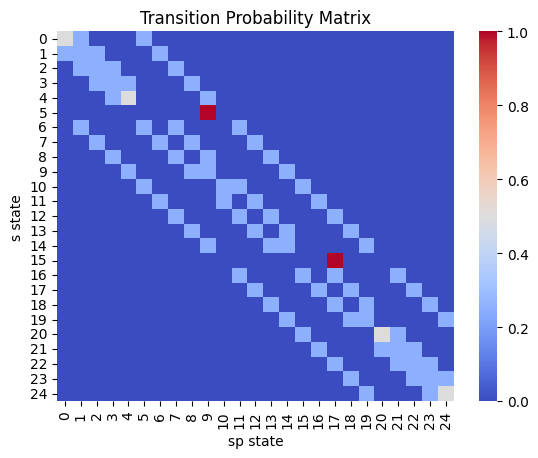

In [73]:
# PLOT TRANSITION MATRIX
conf = {
    'title': 'Transition Probability Matrix',
    'xlabel': 'sp state',
    'ylabel': 's state'
}
plot_heatmap(grid.TrPrM, **conf)

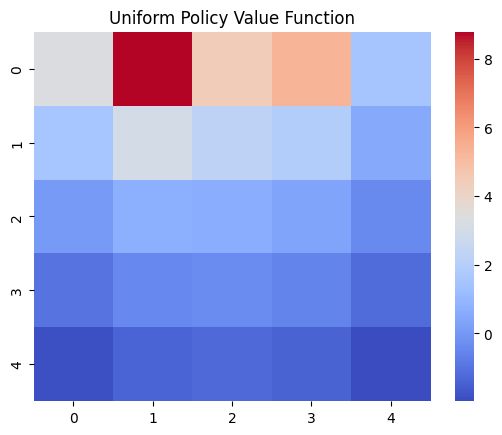

In [74]:
# COMPUTE UNIFORM POLICY VALUE FUNCTION AND PLOT IT

# 4.TODO: Compute Bellman Equation

value_f = np.linalg.solve(np.eye(grid.N_STATES) - grid.GAMMA * grid.TrPrM, grid.REWARD)

vf_matrix = np.transpose(np.reshape(value_f, (grid.N_ROWS, grid.N_COLUMNS)))
conf = {
    'title': 'Uniform Policy Value Function',
}
plot_heatmap(vf_matrix, **conf)

## PREDICTION - ITERATIVE POLICY EVALUATION (IPE,d)

In [75]:
'''
In this case we define a function since we will use this algorithm
within 'policy iteration' algorithm
'''
def policy_evaluation(grid):
    zeta = grid.ZETA_MAX + 1
    iter = 0
    v_incr = []

    while zeta > grid.ZETA_MAX and iter < grid.ITER_MAX + 1:

        vm_aux = grid.V_FUNCTION.copy()                                 # Store current state-values for later comparison

        for s in range(1, grid.N_STATES + 1):                           # Loop over all the states
            vs_aux = 0
            for a in range(grid.N_ACTIONS):                             # Loop over all actions in each state
                next_state, reward = grid.next_position(s, a)           # Compute next_state and reward when taking action a in state s

                 # 5.TODO: Compute the update of the state value
                vs_aux += grid.POLICY[s - 1, a] * (reward + grid.GAMMA * grid.V_FUNCTION[next_state - 1])

            grid.V_FUNCTION[s - 1] = vs_aux                             # Update state-value with the result of Bellman Equation

        zeta = np.max(np.abs(grid.V_FUNCTION - vm_aux))                 # Compute the difference between current state-values and previous ones
        v_incr.append(zeta)
        iter += 1

    return v_incr

In [84]:
grid = Grid()
v_incr = policy_evaluation(grid)

print(grid.ZETA_MAX)
print(len(v_incr))
print(v_incr[-1])
print(np.max(np.abs(grid.V_FUNCTION - value_f)))

0.001
30
0.0009067517584120388
0.0045992586669765245


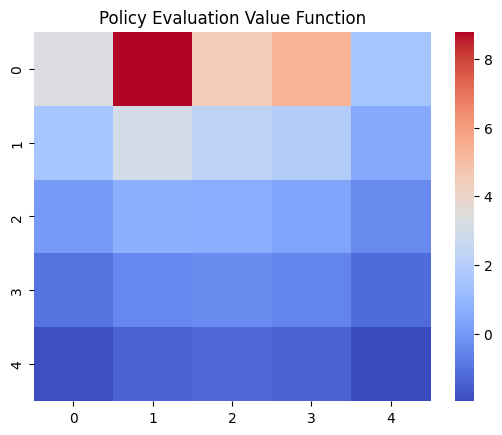

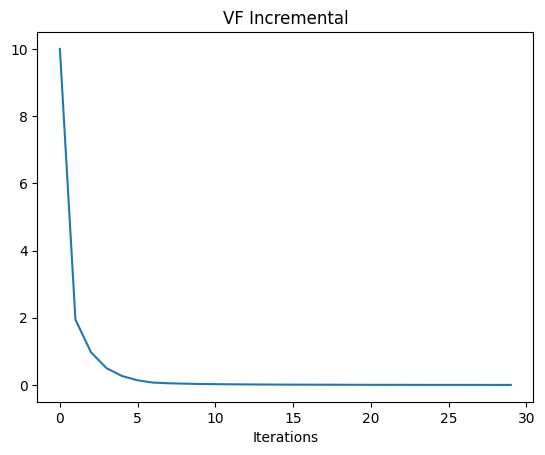

In [77]:
vf_matrix = np.transpose(np.reshape(grid.V_FUNCTION, (grid.N_ROWS, grid.N_COLUMNS)))

conf = {
    'title': 'Policy Evaluation Value Function',
}
plot_heatmap(vf_matrix, **conf)


conf= {
    'title': 'VF Incremental',
    'xlabel': 'Iterations'
}
plot_deltas(v_incr, **conf)


**d):** IPE converges in 30 iterations with $\theta = 10^{-3}$. The maximum difference with the closed form solution of c) is $\approx 0.005$, so both value functions coincide up to the tolerance. The residual error comes from the stopping criteria ($\text{error} \leq\frac{\gamma}{1-\gamma}\,\theta$) and decreases with a smaller $\theta$.

## CONTROL - POLICY ITERATION  (PI,e)

In [85]:
grid = Grid()

iter = 0
it_max = 10
ac_dif = 1

actions_list = []       # Store actions taken in each state for each run. [[a1, ... , a25], ... , [a1, ... , a25]]
a_inc = []              # Store number of different actions taken in each run.
pe_sweeps = []


while ac_dif > 0 and iter < it_max + 1:
    ac_dif = 0
    actions = []        # Store actions taken in each state in one run. [a1, ..., a25]

# 6.TODO: Program Policy Iteration Algorithm (you must make use of policy_evaluation function)
    pe_sweeps.append(len(policy_evaluation(grid)))

    for s in range(1, grid.N_STATES + 1):
        q = np.zeros(grid.N_ACTIONS)
        for a in range(grid.N_ACTIONS):
            next_state, reward = grid.next_position(s, a)
            q[a] = reward + grid.GAMMA * grid.V_FUNCTION[next_state - 1]

        best_a = np.argmax(q)
        if grid.POLICY[s - 1, best_a] != 1:
            ac_dif += 1

        grid.POLICY[s - 1] = 0
        grid.POLICY[s - 1, best_a] = 1
        actions.append(best_a)


    #####

    actions_list.append(np.transpose(np.array(actions).reshape(grid.N_ROWS,grid.N_COLUMNS)))
    a_inc.append(ac_dif)

    iter += 1

print('theta:', grid.ZETA_MAX)
print('outer iterations:', iter)
print('changed actions per iteration:', a_inc)
print('inner policy evaluation iterations K:', pe_sweeps)
print('v_pi(6), v_A(6):', value_f[5], grid.V_FUNCTION[5])
print('v_pi(16), v_A(16):', value_f[15], grid.V_FUNCTION[15])
print('v_pi(25), v_A(25):', value_f[24], grid.V_FUNCTION[24])
print('min, max of v_A - v_pi:', np.min(grid.V_FUNCTION - value_f), np.max(grid.V_FUNCTION - value_f))

v_PI = grid.V_FUNCTION.copy()


theta: 0.001
outer iterations: 3
changed actions per iteration: [25, 15, 0]
inner policy evaluation iterations K: [30, 28, 3]
v_pi(6), v_A(6): 8.789291862596123 24.419425957777065
v_pi(16), v_A(16): 5.3223675933702115 19.419425957777065
v_pi(25), v_A(25): -1.9751790482770988 11.679735735384304
min, max of v_A - v_pi: 13.654914783661402 19.04156443618107


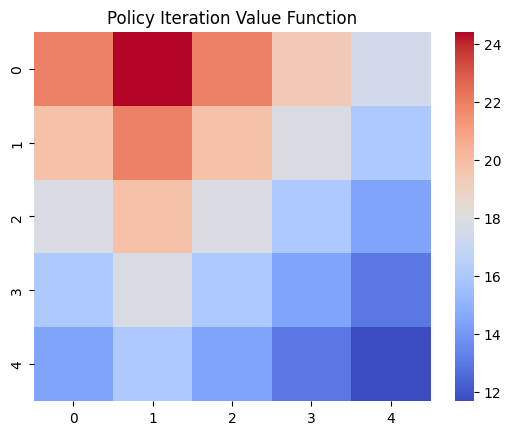

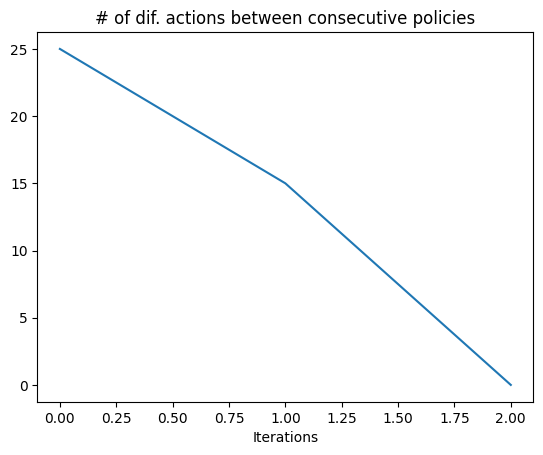

In [79]:
vf_matrix = np.transpose(np.reshape(grid.V_FUNCTION, (grid.N_ROWS, grid.N_COLUMNS)))

conf = {
    'title': 'Policy Iteration Value Function',
}
plot_heatmap(vf_matrix, **conf)


conf= {
    'title': '# of dif. actions between consecutive policies',
    'xlabel': 'Iterations'
}
plot_deltas(a_inc, **conf)



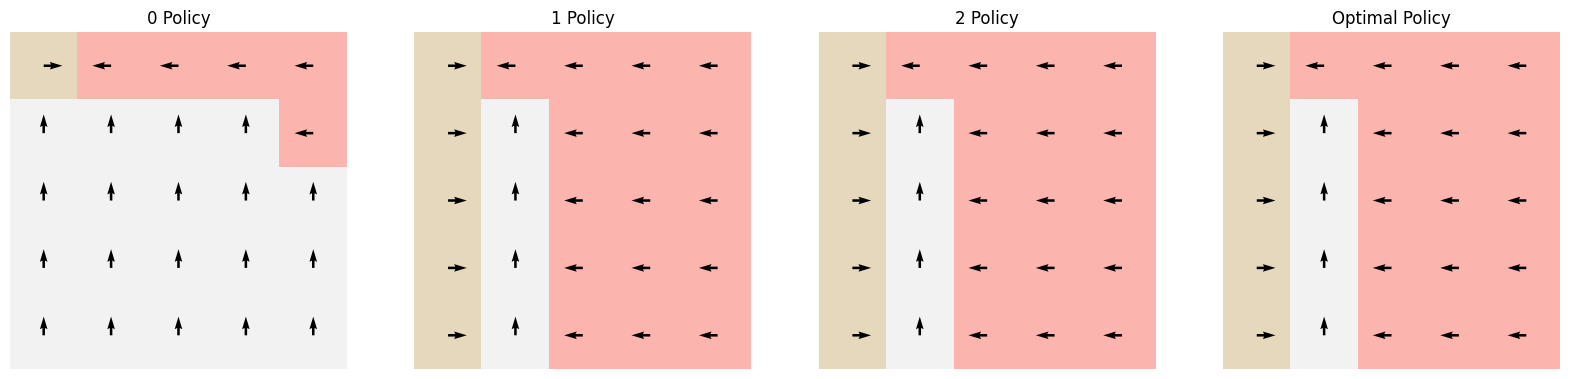

In [80]:
plot_arrows(actions_list, grid.ACTIONS)

**e):** I use $\theta = 10^{-3}$ as the stopping criteria of the inner policy evaluation. Policy Iteration converges in 3 outer iterations, with $25$, $15$ and $0$ changed actions. The last iteration changes no action, so the policy is stable and satisfies the Bellman optimality equation. The inner loop takes $K = 30$, $28$ and $3$ iterations. Each evaluation starts from the previous $v$ so it needs fewer iterations as the policy stops changing. $v_A(s) > v_\pi(s)$ in every state with increases between $13.7$ and $19.0$. For state 6, $v_\pi(6) = 8.79$ and $v_A(6) = 24.42$. This agrees with the policy improvement theorem. The random policy wastes steps and gets $-1$ at the walls, while $A(s)$ takes every state straight to state 6, which gives $+10$.

## CONTROL - VALUE ITERATION (VI,f)

In [81]:

grid = Grid()
zeta = grid.ZETA_MAX + 1
iter = 0
v_incr = []
a_inc = []

while zeta > grid.ZETA_MAX and iter < grid.ITER_MAX + 1:
    ac_dif = 0
    vm_aux = grid.V_FUNCTION.copy()

    # 7.TODO: Program Value Iteration Algorithm (do NOT make use of policy_evaluation function)

    for s in range(1, grid.N_STATES + 1):
        q = np.zeros(grid.N_ACTIONS)
        for a in range(grid.N_ACTIONS):
            next_state, reward = grid.next_position(s, a)
            q[a] = reward + grid.GAMMA * grid.V_FUNCTION[next_state - 1]

        best_a = np.argmax(q)
        if grid.POLICY[s - 1, best_a] != 1:
            ac_dif += 1

        grid.V_FUNCTION[s - 1] = q[best_a]
        grid.POLICY[s - 1] = 0
        grid.POLICY[s - 1, best_a] = 1


    #####

    a_inc.append(ac_dif)                                # Number of actions taken differently from previous iteration
    zeta = np.max(np.abs(grid.V_FUNCTION - vm_aux))     # Compute the difference of the state-values
    v_incr.append(zeta)                                 # Store the difference in v_incr list
    iter += 1

print('theta:', grid.ZETA_MAX)
print('iterations:', iter)
print('last iteration with changed actions:', max(i for i, n in enumerate(a_inc) if n > 0) + 1)
print('v_pi(6), v_VI(6):', value_f[5], grid.V_FUNCTION[5])
print('min, max of v_VI - v_pi:', np.min(grid.V_FUNCTION - value_f), np.max(grid.V_FUNCTION - value_f))
print('max |v_VI - v_PI|:', np.max(np.abs(grid.V_FUNCTION - v_PI)))


theta: 0.001
iterations: 20
last iteration with changed actions: 2
v_pi(6), v_VI(6): 8.789291862596123 24.41877948282368
min, max of v_VI - v_pi: 13.654605576695271 19.04104079146883
max |v_VI - v_PI|: 0.0009853299091275858


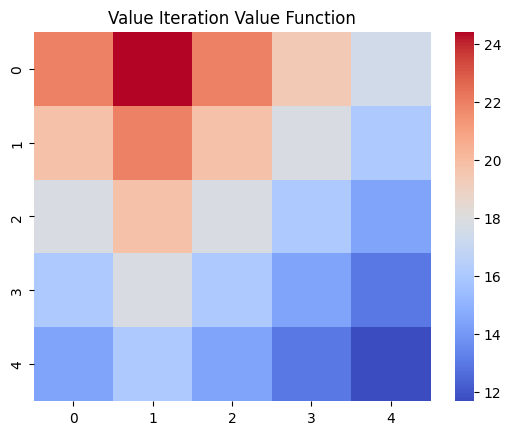

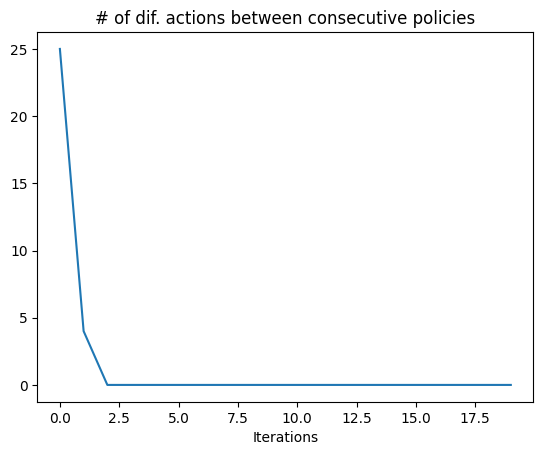

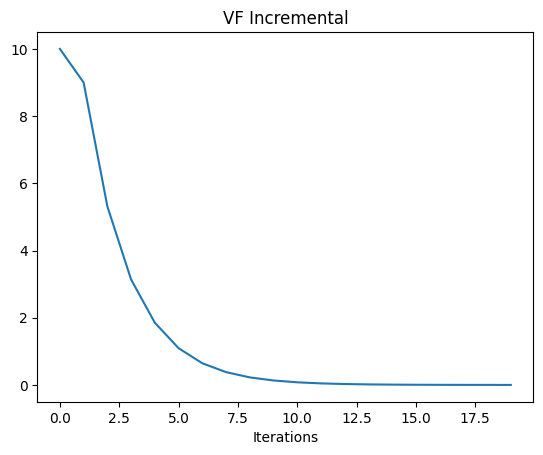

In [82]:
vf_matrix = np.transpose(np.reshape(grid.V_FUNCTION, (grid.N_ROWS, grid.N_COLUMNS)))

conf = {
    'title': 'Value Iteration Value Function',
}
plot_heatmap(vf_matrix, **conf)


conf= {
    'title': '# of dif. actions between consecutive policies',
    'xlabel': 'Iterations'
}
plot_deltas(a_inc, **conf)

conf= {
    'title': 'VF Incremental',
    'xlabel': 'Iterations'
}
plot_deltas(v_incr, **conf)


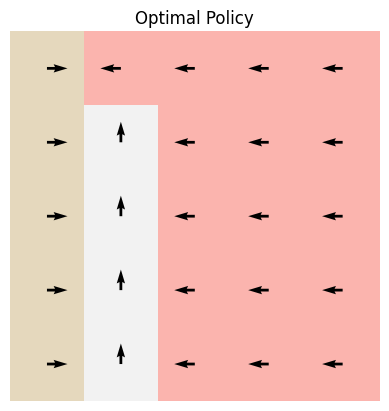

In [83]:
conf= {
    'title': 'Optimal Policy'
}

actions = [np.argmax(grid.POLICY[s-1]) for s in range(1, grid.N_STATES + 1)]
action_arrows = np.transpose(np.array(actions).reshape(grid.N_ROWS,grid.N_COLUMNS))
plot_arrow(action_arrows, grid.ACTIONS, **conf)

**f):** With the same $\theta = 10^{-3}$ Value Iteration needs 20 iterations. The policy is already fixed after the second one and the rest of the iterations just polish the values until the change drops below $\theta$. This is cheaper than Policy Iteration which ran 61 policy evaluation iterations in total plus the improvement steps. Here each iteration is a single update that takes the max over the actions with no full evaluations.

The value function we get is basically the same one as in e). The largest difference between the two is $0.001$ and both give $v_A(6) \approx 24.42$. So both methods land on the same optimal solution, they just go there differently. Against the random policy of c) the gain is of course the same as before, between $13.7$ and $19.0$ in every state.